In [1]:
# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.


In [2]:
# %% [markdown]
## 1. Imports & Setup

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
from scipy.stats import beta

warnings.filterwarnings('ignore')
cp.random.seed(42)

In [3]:
# %% [markdown]
## 2. Global Parameters & GPU Constants

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR+1))
DISCOUNT = 0.035
POP_SIZE = 62000

# Demographics
SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST = cp.array([
    0.064,0.067,0.069,0.069,0.071,0.076,0.080,0.077,0.080,
    0.079,0.073,0.078,0.077,0.072,0.055,0.041,0.031,0.022,0.012
])
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54])
ABS_MORT = cp.array([
    0.0002,0.0001,0.0001,0.0002,0.0003,0.0005,0.0007,0.0011,0.0019,
    0.0035,0.0055,0.0085,0.0130,0.0200,0.0350,0.0600,0.0950,0.1500,0.2500
])
MORT_HR = cp.array([2.0, 4.0])

defaul_yield = 0.45

# Fertility bands
FERT_AGE_SPEC = {
    (0, (15, 19)): 0.003, (0, (20, 24)): 0.008, (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007, (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001, (1, (20, 24)): 0.003, (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003, (1, (35, 45)): 0.001
}
# Build GPU lookup table for fertility rates
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi+1):
        fert_data.append({'severity': s, 'age': age, 'rate': r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78, 0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs
COST_INP_CP = cp.array([5000, 15000])
COST_OUTP_CP = cp.array([1000, 3000])
COST_PHARM_CP = cp.array([200, 500])
EDU0 = cp.array([16107, 27903, 46733])
EDU1 = cp.array([18958, 30789, 49604])
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000, 8000])
EMP_CP = cp.array([0, 10000, 0])

# Morbidity
MORB_KEYS = ['epilepsy', 'asd', 'mental']
MORB_PROB = {'epilepsy': 0.25, 'asd': 0.30, 'mental': 0.35}
MORB_COST_CP = cp.array([2000, 1500, 1000])
MORB_QALY_CP = cp.array([0.04, 0.03, 0.05])

In [4]:
# %% [markdown]
## 3. Cohort Generator (GPU)

def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, familial_prop, arm='prospective'):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    diag = cp.zeros(n, bool) if arm == 'prospective' else (cp.random.random(n) < defaul_yield)
    living = cp.random.choice(4, n, p=cp.array([0.2,0.1,0.3,0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7,0.2,0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5,0.3,0.2]))
    ses = cp.random.choice(5, n)
    df = cudf.DataFrame({
        'age': ages, 'sex': sex, 'severity': sev, 'familial': familial,
        'diagnosed': diag, 'living': living, 'employment': employment,
        'uses_respite': uses_respite, 'needs_mobility': needs_mobility,
        'school': school, 'support': support, 'ses': ses
    })
    df['annual_cost'] = 0.0; df['annual_qaly'] = 0.0
    return df

In [5]:
# %% [markdown]
## 4. Population System (GPU)

class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm='prospective'):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df['age'].to_cupy(); sev = df['severity'].to_cupy()
        surv = ABS_MORT[(ages//5).astype(int)] * MORT_HR[sev]
        mask = (cp.random.random(len(ages)) > surv) & (ages < LIFE_EXP_CP[sev])
        self.pop = df.iloc[cp.where(mask)[0]].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df['sex']==0) & df['age'].between(15,45)]
        if moms.empty: return
        mr = moms.merge(FERT_RATES_GPU, on=['severity','age'], how='left').fillna({'rate':0})
        rates = mr['rate'].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]
        if len(idx)>0:
            babies = gen_population_gpu(len(idx), familial_prop, self.arm)
            babies['age'] = 0
            flags = mr['familial'].iloc[idx.get()].reset_index(drop=True)
            babies['familial'] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self, params):
        if self.arm != 'prospective': return
        df = self.pop
        mask = (~df['diagnosed']) & df['familial'] & (df['age'] >= params.get('min_test_age', 0))
        cnt = int(mask.sum())
        if cnt>0:
            df.loc[mask, 'diagnosed'] = cp.random.random(cnt) < params['yield_wgs']
        self.pop = df

    def _cost_qaly(self, year, params):
        df = self.pop; disc = 1/((1+DISCOUNT)**(year-START_YEAR))
        sev = df['severity'].to_cupy(); ages = df['age'].to_cupy()
        hc = (COST_INP_CP[sev] + COST_OUTP_CP[sev] + COST_PHARM_CP[sev]) * disc
        m0 = df['school']==0; m1 = df['school']==1
        ec0 = EDU0[df.loc[m0,'support'].to_cupy()] * disc
        ec1 = EDU1[df.loc[m1,'support'].to_cupy()] * disc
        rc = df['uses_respite'].astype(int) * RESPITE * disc
        mc = -df['needs_mobility'].astype(int) * MOBILITY * disc
        wc = WELFARE_CP[sev] * disc
        emp = EMP_CP[df['employment'].to_cupy()] * disc
        base = cp.random.random(len(df))
        morb_cost = cp.zeros(len(df)); morb_qaly = cp.zeros(len(df))
        for i, k in enumerate(MORB_KEYS):
            m = (base < MORB_PROB[k])
            morb_cost += m.astype(float) * MORB_COST_CP[i] * disc
            morb_qaly += m.astype(float) * MORB_QALY_CP[i] * disc
        uq = U_BASE_CP[sev] * cp.exp(-U_DECAY * cp.clip(ages-20,0,None))
        total_qaly = (uq + df['diagnosed'].astype(int)*U_DIAG + U_CARER) * disc - morb_qaly
        df['cost_health'] = hc; df['cost_edu'] = 0.0
        df.loc[m0,'cost_edu'] = ec0; df.loc[m1,'cost_edu'] = ec1
        df['cost_respite'] = rc; df['cost_mobility'] = mc
        df['cost_welfare'] = wc; df['cost_emp'] = emp
        df['cost_morbidity'] = morb_cost
        df['annual_cost'] = hc + df['cost_edu'] + rc + mc + wc + emp + morb_cost
        df['annual_qaly'] = total_qaly
        self.pop = df

    def step(self, year, params):
        self._mortality(); self._fertility(params['familial_prop'])
        self._diagnosis(params); self._cost_qaly(year, params)


In [6]:
# %% [markdown]
## 5. Run Helpers

from copy import deepcopy

def run_sim(params, pop_size=POP_SIZE):
    sim_r = PopulationSystemGPU(pop_size, params['familial_prop'], 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, params['familial_prop'], 'prospective')
    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0
    for yr in YEARS:
        sim_r.step(yr, params); df_r = sim_r.pop
        sim_p.step(yr, params); df_p = sim_p.pop
        cum_r_c += float(df_r['annual_cost'].sum()); cum_r_q += float(df_r['annual_qaly'].sum())
        cum_p_c += float(df_p['annual_cost'].sum()); cum_p_q += float(df_p['annual_qaly'].sum())
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(params, pop_size=POP_SIZE):
    sim_r = PopulationSystemGPU(pop_size, params['familial_prop'], 'retrospective')
    sim_p = PopulationSystemGPU(pop_size, params['familial_prop'], 'prospective')
    outputs = []
    for arm, sim in [('retrospective', sim_r), ('prospective', sim_p)]:
        cum_c = cum_q = 0.0
        for yr in YEARS:
            sim.step(yr, params); df = sim.pop
            hc = float(df['cost_health'].sum()); edu = float(df['cost_edu'].sum())
            rc = float(df['cost_respite'].sum()); mob = float(df['cost_mobility'].sum())
            wc = float(df['cost_welfare'].sum()); emp = float(df['cost_emp'].sum())
            mc = float(df['cost_morbidity'].sum())
            cum_c += float(df['annual_cost'].sum()); cum_q += float(df['annual_qaly'].sum())
            pct = lambda i: float((df['ses']==i).mean()*100)
            outputs.append({
                'arm': arm, 'year': yr,
                'cost_health': hc, 'cost_edu': edu, 'cost_respite': rc,
                'cost_mobility': mob, 'cost_welfare': wc,
                'cost_emp': emp, 'cost_morbidity': mc,
                'costs': cum_c, 'qalys': cum_q,
                **{f'ses_q{i}_pct': pct(i) for i in range(5)}
            })
    return run_sim(params, pop_size), cudf.DataFrame(outputs)

  scenario         dCost        dQALY           ICER
0      low  1.698129e+08   705.772772  240605.589987
1     base -8.641694e+07 -3888.754172   22222.267562
2     high -1.397908e+08 -4399.793334   31772.138006


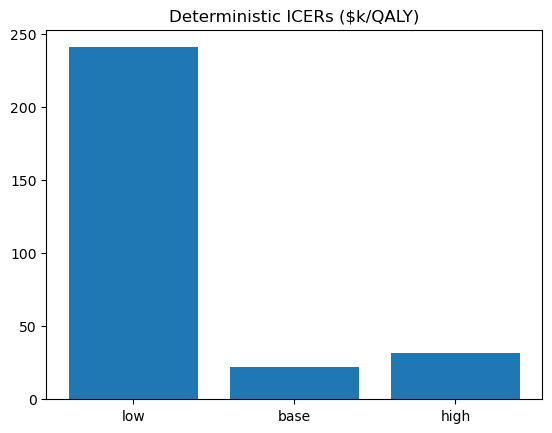

In [7]:
# %% [markdown]
## 6. Deterministic Scenarios

scenarios = {'low': 0.10, 'base': 0.165, 'high': 0.23}
results = []
for name, val in scenarios.items():
    dc, dq = run_sim({'familial_prop': val, 'yield_wgs': defaul_yield}, pop_size=20000)
    results.append({'scenario': name, 'dCost': dc, 'dQALY': dq, 'ICER': dc/dq})
det_df = cudf.DataFrame(results)
det_df.to_csv('deterministic_summary.csv', index=False)
print(det_df)
plt.bar(det_df['scenario'].to_arrow().to_pylist(), [x/1000 for x in det_df['ICER'].to_arrow().to_pylist()])
plt.title('Deterministic ICERs ($k/QALY)'); plt.show()

In [ ]:
# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

psa_n = 300
psa_out = []
for i in range(psa_n):
    samp = {
        'familial_prop': beta.rvs(30, 150),
        'yield_wgs': beta.rvs(45, 55)
    }
    dc, dq = run_sim(samp, pop_size=8000)
    psa_out.append({'run': i, 'dCost': dc, 'dQALY': dq})
psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv('psa_samples.csv', index=False)

In [ ]:
# %% [markdown]
## 8. CE-Plane, CEAC & EVPI

wtp = cp.linspace(0,150000,40)
dcost = psa_df['dCost'].to_cupy()
dqaly = psa_df['dQALY'].to_cupy()
nb = dqaly[:, None] * wtp[None, :] - dcost[:, None]
# CE-Plane scatter
plt.scatter(dqaly.get(), dcost.get()); plt.xlabel('ΔQALY'); plt.ylabel('ΔCost'); plt.title('CE-Plane'); plt.show()
# CEAC
prob = (nb > 0).mean(axis=0)
plt.plot(wtp.get(), prob.get()); plt.title('CEAC'); plt.xlabel('WTP'); plt.ylabel('P(cost-effective)'); plt.show()
# EVPI
evpi = nb.max(axis=0) - cp.maximum(nb.mean(axis=0), 0)
plt.plot(wtp.get(), evpi.get()); plt.title('EVPI'); plt.xlabel('WTP'); plt.ylabel('EVPI'); plt.show()


In [ ]:
# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

tornado = []
for param in ['yield_wgs','familial_prop']:
    base = defaul_yield if param=='yield_wgs' else 0.165
    for change in [-0.2,0.2]:
        p = {'familial_prop':0.165,'yield_wgs':defaul_yield}
        p[param] = base * (1+change)
        dc, dq = run_sim(p, pop_size=10000)
        tornado.append({'param':param, 'change':f'{int(change*100)}%', 'ICER': dc/dq})
tor_df = cudf.DataFrame(tornado)
labels = [f"{p} {c}" for p,c in zip(tor_df['param'].to_arrow().to_pylist(), tor_df['change'].to_arrow().to_pylist())]
icers = tor_df['ICER'].to_arrow().to_pylist()
plt.figure(); plt.barh(labels, [x/1000 for x in icers]); plt.xlabel('ICER ($k/QALY)'); plt.title('Tornado Sensitivity'); plt.show()

In [ ]:
# %% [markdown]
## 10. Subgroup Analyses

sg = []
# Severity
orig = SEVERITY_DIST.copy()
for sev,label in [(0,'Mild'),(1,'Moderate')]:
    SEVERITY_DIST[:] = cp.array([1.0 if i==sev else 0.0 for i in range(2)])
    res,_ = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=15000)
    ic = res[0]/res[1]
    sg.append({'group':f"Severity {label}", 'ICER': ic})
SEVERITY_DIST[:] = orig
# Age-at-test
for age in [0,18,30]:
    res,_ = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield,'min_test_age':age}, pop_size=15000)
    ic = res[0]/res[1]
    sg.append({'group':f"MinTestAge {age}", 'ICER': ic})
# Time-horizon
res_full, int_full = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=15000)
for yrs_n in [10,20,len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    dfp = int_full[int_full['arm']=='prospective']
    dfr = int_full[int_full['arm']=='retrospective']
    c1 = dfp.loc[dfp['year']==yr,'costs'].to_arrow().to_pylist()[0]
    c0 = dfr.loc[dfr['year']==yr,'costs'].to_arrow().to_pylist()[0]
    q1 = dfp.loc[dfp['year']==yr,'qalys'].to_arrow().to_pylist()[0]
    q0 = dfr.loc[dfr['year']==yr,'qalys'].to_arrow().to_pylist()[0]
    sg.append({'group':f"Horizon {yrs_n}yrs", 'ICER': (c1-c0)/(q1-q0)})
sg_df = cudf.DataFrame(sg)
labels = sg_df['group'].to_arrow().to_pylist()
icers = sg_df['ICER'].to_arrow().to_pylist()
plt.figure(); plt.errorbar(icers, labels, xerr=[0]*len(icers), fmt='o'); plt.xlabel('ICER ($/QALY)'); plt.title('Subgroup Analyses'); plt.show()


In [ ]:
# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

_, mix = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)
pm = mix[mix['arm']=='prospective']
cost_cols = ['cost_health','cost_edu','cost_respite','cost_mobility','cost_welfare','cost_emp','cost_morbidity']
years_host = pm['year'].to_arrow().to_pylist()
data = [pm[col].to_arrow().to_pylist() for col in cost_cols]
plt.figure(); plt.stackplot(years_host, *data, labels=cost_cols); plt.legend(loc='upper left'); plt.title('Cost Mix Over Time (Prospective)'); plt.xlabel('Year'); plt.ylabel('Cumulative Cost'); plt.show()


In [ ]:
# %% [markdown]
## 12. 5-Year Budget Impact

budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
for u in uptakes:
    _, df = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)
    dfp = df[df['arm']=='prospective']; dfr = df[df['arm']=='retrospective']
    for yr in yrs:
        c1 = dfp.loc[dfp['year']==yr,'costs'].to_arrow().to_pylist()[0]
        c0 = dfr.loc[dfr['year']==yr,'costs'].to_arrow().to_pylist()[0]
        budg.append({'uptake':u,'year':yr,'delta_cost':c1-c0})
budg_df = cudf.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df['uptake']==u]
    yrs_h = sub['year'].to_arrow().to_pylist()
    vals = sub['delta_cost'].to_arrow().to_pylist()
    plt.plot(yrs_h, vals, label=f"Uptake {int(u*100)}%")
plt.title('5-Year Budget Impact'); plt.xlabel('Year'); plt.ylabel('ΔCost'); plt.legend(); plt.show()

In [ ]:
# %% [markdown]
## 13. Equity by SES Quintile

eq_int = run_scenario({'familial_prop':0.165,'yield_wgs':defaul_yield}, pop_size=20000)[1]
bas = eq_int[eq_int['arm']=='prospective']
row = bas[bas['year']==YEARS[-1]].iloc[0]
ses_cols = [f'ses_q{i}_pct' for i in range(5)]
ses_vals = [row[col] for col in ses_cols]
labels = ses_cols; vals = [float(v) for v in ses_vals]
plt.figure(); plt.bar(labels, vals); plt.title('SES Equity by Quintile (Last Year)'); plt.xlabel('SES Quintile'); plt.ylabel('Percentage (%)'); plt.show()


In [ ]:
# %% [markdown]
## 14. PSA Histograms

cost_list = psa_df['dCost'].to_arrow().to_pylist()
qaly_list = psa_df['dQALY'].to_arrow().to_pylist()
plt.figure(); plt.hist(cost_list, bins=30); plt.title('PSA ΔCost'); plt.show()
plt.figure(); plt.hist(qaly_list, bins=30); plt.title('PSA ΔQALY'); plt.show()